In [11]:
!sudo apt-get update -qq
!sudo apt-get install -y libopencv-dev pkg-config


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu/dists/noble/InRelease  503  Service Unavailable [IP: 185.125.189.186 443]
W: Some index files failed to download. They have been ignored, or old ones used instead.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  l

In [12]:
from pathlib import Path

for nom in ["scene1.row3.col1.ppm", "scene1.row3.col3.ppm"]:
    fichiers = list(Path("/content").rglob(nom))
    print(nom, ":", fichiers if fichiers else "INTROUVABLE")

scene1.row3.col1.ppm : [PosixPath('/content/scene1.row3.col1.ppm')]
scene1.row3.col3.ppm : [PosixPath('/content/scene1.row3.col3.ppm')]


In [14]:
%%writefile /content/stereo.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <filesystem>
using namespace cv;
using namespace std;
namespace fs = std::filesystem;

string chercher(string nom) {
    for (const auto& f : fs::recursive_directory_iterator(
             "/content", fs::directory_options::skip_permission_denied)) {
        if (f.is_regular_file() && f.path().filename() == nom)
            return f.path().string();
    }
    return "";
}

int main() {
    string cheminSol = chercher("scene1.row3.col1.ppm");
    string cheminSag = chercher("scene1.row3.col3.ppm");

    if (cheminSol.empty() || cheminSag.empty()) {
        cout << "Resimler bulunamadi!" << endl;
        return 1;
    }

    Mat sol = imread(cheminSol);
    Mat sag = imread(cheminSag);

    if (sol.empty() || sag.empty() || sol.size() != sag.size()) {
        cout << "Resimler okunamadi veya boyutlari farkli!" << endl;
        return 1;
    }

    Mat griSol, griSag;
    cvtColor(sol, griSol, COLOR_BGR2GRAY);
    cvtColor(sag, griSag, COLOR_BGR2GRAY);

    int numDisp = 128;
    int blockSize = 15;

    if (sol.cols <= numDisp + blockSize) {
        numDisp = ((sol.cols - blockSize - 1) / 16) * 16;
    }

    if (numDisp < 16) {
        cout << "Goruntu cok kucuk!" << endl;
        return 1;
    }

    Ptr<StereoBM> stereo = StereoBM::create(numDisp, blockSize);
    stereo->setTextureThreshold(5);
    stereo->setUniquenessRatio(10);

    Mat disparite16;
    stereo->compute(griSol, griSag, disparite16);

    Mat gecerli = disparite16 > 0;
    Mat disparite8 = Mat::zeros(sol.size(), CV_8U);

    if (countNonZero(gecerli) > 0) {
        double minimum, maksimum;
        minMaxLoc(disparite16, &minimum, &maksimum,
                  nullptr, nullptr, gecerli);

        if (maksimum > minimum) {
            Mat temp;
            disparite16.convertTo(
                temp, CV_8U,
                255.0 / (maksimum - minimum),
                -minimum * 255.0 / (maksimum - minimum)
            );
            temp.copyTo(disparite8, gecerli);
        }
    }

    Mat renkli;
    applyColorMap(disparite8, renkli, COLORMAP_JET);
    renkli.setTo(Scalar(0,0,0), ~gecerli);

    imwrite("/content/stereo_disparite.png", renkli);

    int w = 400;
    int h = sol.rows * w / sol.cols;

    Mat solK, sagK, dispK;
    resize(sol, solK, Size(w,h));
    resize(sag, sagK, Size(w,h));
    resize(renkli, dispK, Size(w,h));

    Mat sonuc(h + 45, w * 3, CV_8UC3, Scalar(30,30,30));

    solK.copyTo(sonuc(Rect(0,45,w,h)));
    sagK.copyTo(sonuc(Rect(w,45,w,h)));
    dispK.copyTo(sonuc(Rect(2*w,45,w,h)));

    putText(sonuc, "Sol (col1)", Point(10,30),
            FONT_HERSHEY_SIMPLEX, 0.7, Scalar(255,255,255), 2);

    putText(sonuc, "Sag (col3)", Point(w+10,30),
            FONT_HERSHEY_SIMPLEX, 0.7, Scalar(255,255,255), 2);

    putText(sonuc, "StereoBM Disparity", Point(2*w+10,30),
            FONT_HERSHEY_SIMPLEX, 0.65, Scalar(255,255,255), 2);

    imwrite("/content/stereo_resultat.png", sonuc);

    cout << "Islem tamamlandi!" << endl;
    cout << "Gecerli piksel: " << countNonZero(gecerli) << endl;

    return 0;
}

Overwriting /content/stereo.cpp


In [15]:
!g++ -std=c++17 -O2 /content/stereo.cpp -o /content/stereo $(pkg-config --cflags --libs opencv4) && /content/stereo

Islem tamamlandi!
Gecerli piksel: 56815


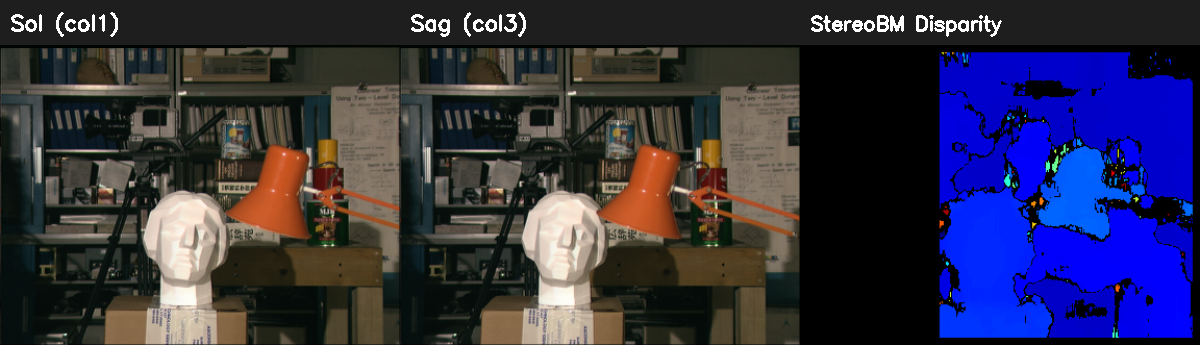

In [16]:
from IPython.display import Image, display
from pathlib import Path

fichier = Path("/content/stereo_resultat.png")

if fichier.exists():
    display(Image(filename=str(fichier)))
else:
    print("Resultat introuvable. Verifiez la compilation C++.")

In [17]:
%%writefile /content/stereo_depth.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <filesystem>

using namespace cv;
using namespace std;
namespace fs = std::filesystem;

string trouver(string nom) {
    for (const auto& f : fs::recursive_directory_iterator("/content")) {
        if (f.is_regular_file() && f.path().filename() == nom)
            return f.path().string();
    }
    return "";
}

int main() {
    string fichierSol = trouver("scene1.row3.col1.ppm");
    string fichierSag = trouver("scene1.row3.col3.ppm");

    Mat sol = imread(fichierSol, IMREAD_COLOR);
    Mat sag = imread(fichierSag, IMREAD_COLOR);

    if (sol.empty() || sag.empty()) {
        cout << "Resimler bulunamadi!" << endl;
        return 1;
    }

    if (sol.size() != sag.size()) {
        cout << "Resim boyutlari farkli!" << endl;
        return 1;
    }

    Mat griSol, griSag;
    cvtColor(sol, griSol, COLOR_BGR2GRAY);
    cvtColor(sag, griSag, COLOR_BGR2GRAY);

    // StereoBM parametreleri
    int numDisparities = 128;
    int blockSize = 15;

    if (sol.cols <= numDisparities + blockSize) {
        numDisparities = ((sol.cols - blockSize - 1) / 16) * 16;
    }

    if (numDisparities < 16) {
        cout << "Resim cok kucuk!" << endl;
        return 1;
    }

    Ptr<StereoBM> stereo = StereoBM::create(
        numDisparities, blockSize
    );

    stereo->setMinDisparity(0);
    stereo->setTextureThreshold(5);
    stereo->setUniquenessRatio(10);
    stereo->setSpeckleWindowSize(100);
    stereo->setSpeckleRange(16);

    // Disparite hesaplama
    Mat disp16, disp32, dispGray;
    stereo->compute(griSol, griSag, disp16);

    // OpenCV dispariteyi 16 kat olcekli saklar
    disp16.convertTo(disp32, CV_32F, 1.0 / 16.0);

    // Gecerli disparite maskesi
    Mat valid = disp32 > 0;

    // 0 - 255 araligina donusturme
    disp32.convertTo(
        dispGray, CV_8U,
        255.0 / numDisparities
    );

    // Hesaplanamayan alanlar siyah
    dispGray.setTo(0, ~valid);

    // Renkli disparite haritasi
    Mat dispColor;
    applyColorMap(dispGray, dispColor, COLORMAP_JET);

    dispColor.setTo(Scalar(0, 0, 0), ~valid);

    // Sonuclari kaydet
    imwrite("/content/disparity_gray.png", dispGray);
    imwrite("/content/disparity_color.png", dispColor);

    // Iki sonucu yan yana goster
    int w = 500;
    int h = max(1, sol.rows * w / sol.cols);

    Mat grayBGR, a, b;
    cvtColor(dispGray, grayBGR, COLOR_GRAY2BGR);

    resize(grayBGR, a, Size(w, h));
    resize(dispColor, b, Size(w, h));

    Mat sonuc(h + 50, 2*w, CV_8UC3, Scalar(30,30,30));

    a.copyTo(sonuc(Rect(0, 50, w, h)));
    b.copyTo(sonuc(Rect(w, 50, w, h)));

    putText(sonuc, "Disparity Map (Gray)",
            Point(20, 32),
            FONT_HERSHEY_SIMPLEX, 0.75,
            Scalar(255,255,255), 2);

    putText(sonuc, "Disparity Map (Color)",
            Point(w+20, 32),
            FONT_HERSHEY_SIMPLEX, 0.75,
            Scalar(255,255,255), 2);

    imwrite("/content/stereo_final.png", sonuc);

    cout << "Islem tamamlandi!" << endl;
    cout << "Gecerli piksel sayisi: "
         << countNonZero(valid) << endl;

    cout << "disparity_gray.png" << endl;
    cout << "disparity_color.png" << endl;
    cout << "stereo_final.png" << endl;

    return 0;
}

Writing /content/stereo_depth.cpp


In [18]:
!g++ -std=c++17 -O2 /content/stereo_depth.cpp -o /content/stereo_depth $(pkg-config --cflags --libs opencv4) && /content/stereo_depth

Islem tamamlandi!
Gecerli piksel sayisi: 55484
disparity_gray.png
disparity_color.png
stereo_final.png


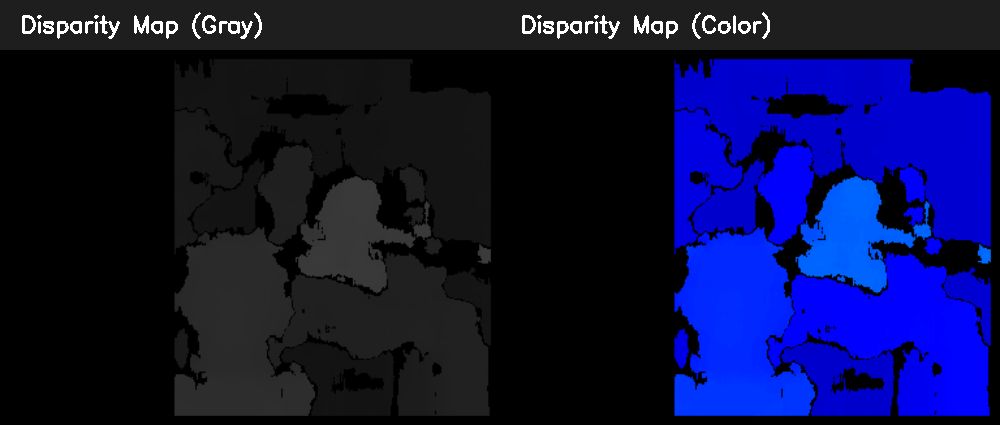

In [19]:
from IPython.display import display, Image
from pathlib import Path

fichier = Path("/content/stereo_final.png")

if fichier.exists():
    display(Image(filename=str(fichier)))
else:
    print("Sonuc bulunamadi. C++ programini kontrol edin.")

In [20]:

%%writefile /content/stereo_manual.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <filesystem>
#include <climits>
using namespace cv;
using namespace std;
namespace fs = std::filesystem;

string trouver(string nom) {
    for (const auto& f : fs::recursive_directory_iterator("/content")) {
        if (f.is_regular_file() && f.path().filename() == nom)
            return f.path().string();
    }
    return "";
}

int calculSAD(const Mat& sol, const Mat& sag,
              int x, int y, int d, int r, int limite) {
    int somme = 0;

    for (int i = -r; i <= r; i++) {
        const uchar* pSol = sol.ptr<uchar>(y + i);
        const uchar* pSag = sag.ptr<uchar>(y + i);

        for (int j = -r; j <= r; j++) {
            int a = pSol[x + j];
            int b = pSag[x - d + j];

            somme += abs(a - b);
        }

        if (somme >= limite)
            return somme;
    }

    return somme;
}

Mat monBlockMatching(const Mat& sol, const Mat& sag,
                     int blockSize, int maxDisp) {

    Mat disparite = Mat::zeros(sol.size(), CV_8UC1);
    int r = blockSize / 2;

    for (int y = r; y < sol.rows - r; y++) {
        for (int x = r; x < sol.cols - r; x++) {

            int meilleurSAD = INT_MAX;
            int meilleurD = 0;

            int limiteD = min(maxDisp, x - r);

            for (int d = 0; d <= limiteD; d++) {

                int sad = calculSAD(
                    sol, sag, x, y, d, r, meilleurSAD
                );

                if (sad < meilleurSAD) {
                    meilleurSAD = sad;
                    meilleurD = d;
                }
            }

            disparite.at<uchar>(y, x) =
                saturate_cast<uchar>(meilleurD * 255.0 / maxDisp);
        }
    }

    return disparite;
}

int main() {

    string fichierSol = trouver("scene1.row3.col1.ppm");
    string fichierSag = trouver("scene1.row3.col3.ppm");

    if (fichierSol.empty() || fichierSag.empty()) {
        cout << "Stereo resimleri bulunamadi!" << endl;
        return 1;
    }

    Mat sol = imread(fichierSol);
    Mat sag = imread(fichierSag);

    if (sol.empty() || sag.empty()) {
        cout << "Resimler okunamadi!" << endl;
        return 1;
    }

    if (sol.size() != sag.size()) {
        cout << "Goruntu boyutlari farkli!" << endl;
        return 1;
    }

    int genislik = min(400, sol.cols);
    int yukseklik = sol.rows * genislik / sol.cols;

    resize(sol, sol, Size(genislik, yukseklik));
    resize(sag, sag, Size(genislik, yukseklik));

    Mat griSol, griSag;
    cvtColor(sol, griSol, COLOR_BGR2GRAY);
    cvtColor(sag, griSag, COLOR_BGR2GRAY);

    int blockSize = 7;
    int maxDisp = min(96, genislik / 3);

    Mat dispGray = monBlockMatching(
        griSol, griSag, blockSize, maxDisp
    );

    Mat dispColor;
    applyColorMap(dispGray, dispColor, COLORMAP_JET);

    imwrite("/content/manual_gray.png", dispGray);
    imwrite("/content/manual_color.png", dispColor);

    Mat sonuc;
    vector<Mat> images = {sol, sag, dispColor};
    hconcat(images, sonuc);

    imwrite("/content/manual_comparison.png", sonuc);

    cout << "Islem tamamlandi!" << endl;
    cout << "Block Size: " << blockSize << endl;
    cout << "Maximum Disparity: " << maxDisp << endl;
    cout << "StereoBM kullanilmadi!" << endl;

    return 0;
}


Writing /content/stereo_manual.cpp


In [21]:
!g++ -std=c++17 -O2 /content/stereo_manual.cpp -o /content/stereo_manual $(pkg-config --cflags --libs opencv4) && /content/stereo_manual

Islem tamamlandi!
Block Size: 7
Maximum Disparity: 96
StereoBM kullanilmadi!


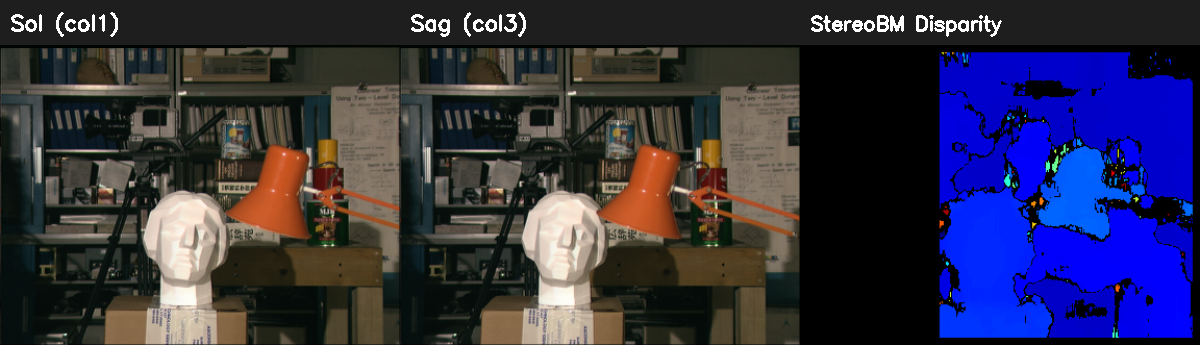

In [23]:
from IPython.display import Image, display

display(Image(filename="/content/stereo_resultat.png"))

In [9]:
%%writefile /content/stereo_matching.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <cmath>
#include <chrono>
#include <string>
using namespace cv;
using namespace std;

using Benzerlik = double (*)(const Mat&, const Mat&);

double SAD(const Mat& a, const Mat& b) {
    double toplam = 0;

    for (int y = 0; y < a.rows; y++) {
        for (int x = 0; x < a.cols; x++) {
            int fark = int(a.at<uchar>(y,x)) - int(b.at<uchar>(y,x));
            toplam += abs(fark);
        }
    }
    return toplam;
}

double SSD(const Mat& a, const Mat& b) {
    double toplam = 0;

    for (int y = 0; y < a.rows; y++) {
        for (int x = 0; x < a.cols; x++) {
            double fark = double(a.at<uchar>(y,x)) - b.at<uchar>(y,x);
            toplam += fark * fark;
        }
    }
    return toplam;
}

double ZNCC(const Mat& a, const Mat& b) {
    double ortA = mean(a)[0];
    double ortB = mean(b)[0];

    double ust = 0, altA = 0, altB = 0;

    for (int y = 0; y < a.rows; y++) {
        for (int x = 0; x < a.cols; x++) {
            double va = a.at<uchar>(y,x) - ortA;
            double vb = b.at<uchar>(y,x) - ortB;

            ust += va * vb;
            altA += va * va;
            altB += vb * vb;
        }
    }

    if (altA < 1e-9 || altB < 1e-9)
        return -2.0;

    return ust / sqrt(altA * altB);
}

Mat eslestir(const Mat& sol, const Mat& sag,
             Benzerlik fonksiyon, bool maksimum,
             int maxDisp, int blok) {

    Mat sonuc = Mat::zeros(sol.size(), CV_8UC1);
    int r = blok / 2;

    for (int y = r; y < sol.rows-r; y++) {
        for (int x = maxDisp+r; x < sol.cols-r; x++) {

            Mat a = sol(Rect(x-r, y-r, blok, blok));

            double enIyi = maksimum ? -2.0 : 1e30;
            int enIyiD = 0;
            bool bulundu = false;

            for (int d = 0; d <= maxDisp; d++) {
                Mat b = sag(Rect(x-d-r, y-r, blok, blok));
                double puan = fonksiyon(a, b);

                if (maksimum && puan < -1.5)
                    continue;

                if (!bulundu ||
                    (maksimum && puan > enIyi) ||
                    (!maksimum && puan < enIyi)) {

                    enIyi = puan;
                    enIyiD = d;
                    bulundu = true;
                }
            }

            if (bulundu) {
                sonuc.at<uchar>(y,x) =
                    saturate_cast<uchar>(
                        255.0 * enIyiD / maxDisp
                    );
            }
        }
    }

    return sonuc;
}

int main() {
    Mat sol = imread("/content/scene1.row3.col1.ppm");
    Mat sag = imread("/content/scene1.row3.col3.ppm");

    if (sol.empty() || sag.empty()) {
        cout << "HATA: Resimler bulunamadi!" << endl;
        return 1;
    }

    if (sol.size() != sag.size()) {
        cout << "HATA: Boyutlar farkli!" << endl;
        return 1;
    }

    int w = min(240, sol.cols);
    int h = max(1, sol.rows * w / sol.cols);

    resize(sol, sol, Size(w,h));
    resize(sag, sag, Size(w,h));

    Mat griSol, griSag;
    cvtColor(sol, griSol, COLOR_BGR2GRAY);
    cvtColor(sag, griSag, COLOR_BGR2GRAY);

    int blok = 5;
    int maxDisp = min(48, (w-blok-1)/2);

    if (maxDisp < 2 || h < blok) {
        cout << "HATA: Resimler cok kucuk!" << endl;
        return 1;
    }

    Benzerlik fonksiyonlar[3] = {SAD, SSD, ZNCC};
    string isimler[3] = {"SAD", "SSD", "ZNCC"};
    bool maksimum[3] = {false, false, true};

    Mat haritalar[3];

    for (int i = 0; i < 3; i++) {
        auto basla = chrono::steady_clock::now();

        haritalar[i] = eslestir(
            griSol, griSag,
            fonksiyonlar[i],
            maksimum[i],
            maxDisp, blok
        );

        auto bitir = chrono::steady_clock::now();

        double sure =
            chrono::duration<double>(bitir-basla).count();

        string griYol =
            "/content/disparity_" + isimler[i] + ".png";

        string renkYol =
            "/content/disparity_" + isimler[i] + "_color.png";

        Mat renkli;
        applyColorMap(haritalar[i], renkli, COLORMAP_JET);
        renkli.setTo(Scalar(0,0,0), haritalar[i] == 0);

        bool k1 = imwrite(griYol, haritalar[i]);
        bool k2 = imwrite(renkYol, renkli);

        cout << isimler[i] << " - Sure: " << sure
             << " saniye - Gray: " << (k1 ? "OK" : "HATA")
             << " - Color: " << (k2 ? "OK" : "HATA")
             << endl;

        if (!k1 || !k2)
            return 1;
    }

    Mat fark;
    absdiff(haritalar[0], haritalar[1], fark);

    if (!imwrite("/content/difference_SAD_SSD.png", fark)) {
        cout << "HATA: Fark haritasi kaydedilemedi!" << endl;
        return 1;
    }

    cout << "SAD-SSD farkli piksel: "
         << countNonZero(fark) << endl;

    cout << "SAD-SSD ortalama fark: "
         << mean(fark)[0] << endl;

    cout << "Tum resimler kaydedildi!" << endl;
    return 0;
}

Overwriting /content/stereo_matching.cpp


In [12]:
!g++ -std=c++17 -O2 /content/stereo_matching.cpp -o /content/stereo_matching $(pkg-config --cflags --libs opencv4) && /content/stereo_matching

SAD - Sure: 0.106387 saniye - Gray: OK - Color: OK
SSD - Sure: 0.10813 saniye - Gray: OK - Color: OK
ZNCC - Sure: 1.00837 saniye - Gray: OK - Color: OK
SAD-SSD farkli piksel: 3802
SAD-SSD ortalama fark: 2.36391
Tum resimler kaydedildi!


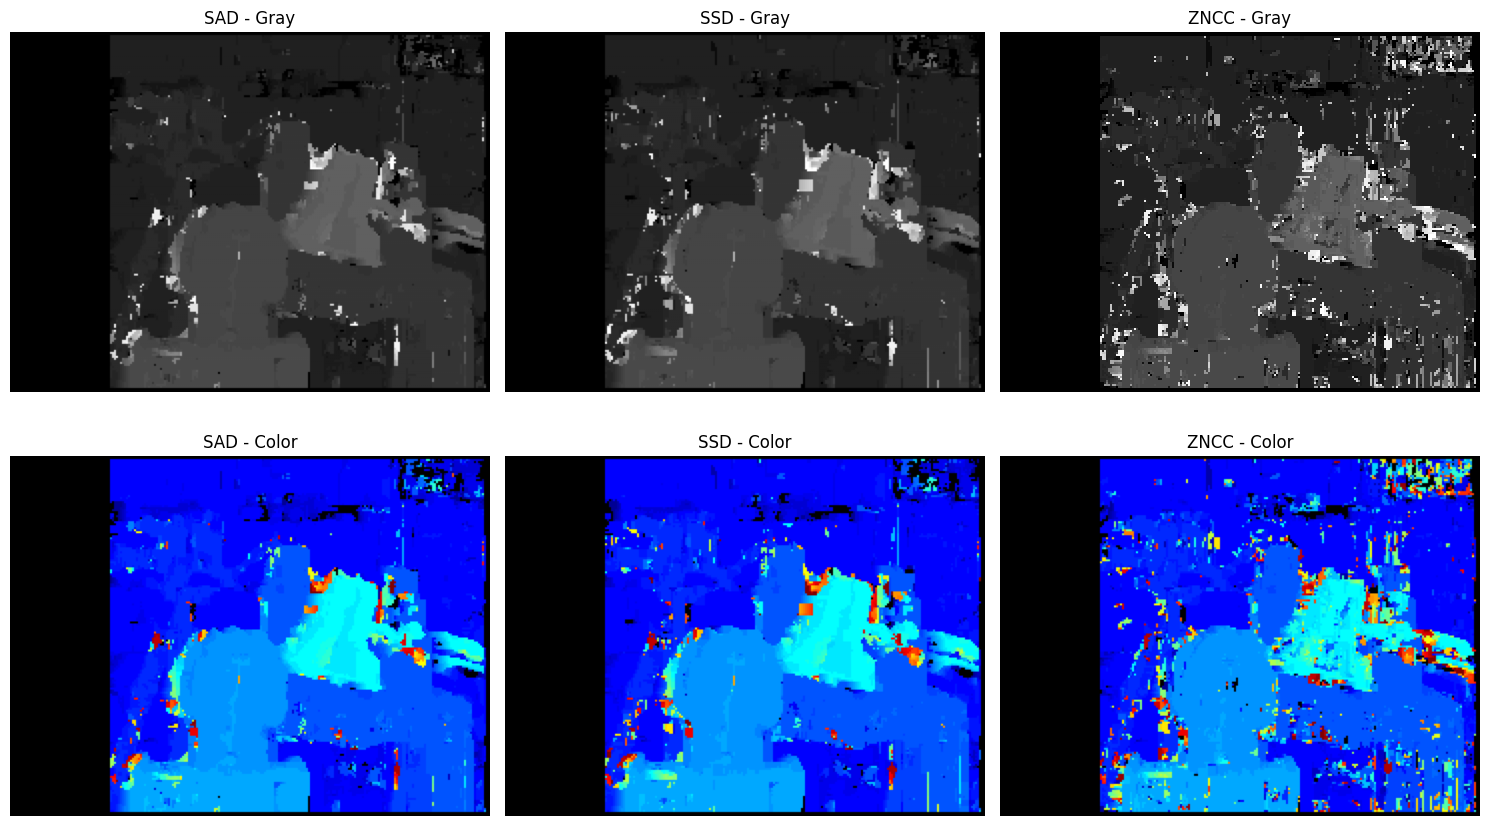

In [13]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

noms = ["SAD", "SSD", "ZNCC"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, nom in enumerate(noms):
    chemin_gray = f"/content/disparity_{nom}.png"
    chemin_color = f"/content/disparity_{nom}_color.png"

    gray = cv2.imread(chemin_gray, 0)
    color = cv2.imread(chemin_color)

    if gray is not None:
        axes[0,i].imshow(gray, cmap="gray", vmin=0, vmax=255)
    else:
        print("Manquant :", chemin_gray)

    if color is not None:
        axes[1,i].imshow(cv2.cvtColor(color, cv2.COLOR_BGR2RGB))
    else:
        print("Manquant :", chemin_color)

    axes[0,i].set_title(nom + " - Gray")
    axes[1,i].set_title(nom + " - Color")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig("/content/stereo_sonuclari.png", dpi=150)
plt.show()

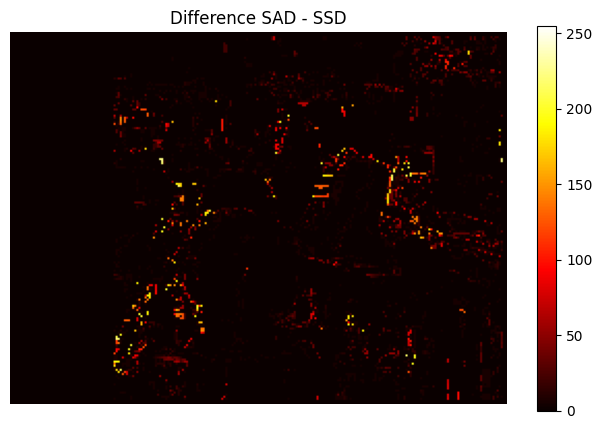

In [14]:
import cv2
import matplotlib.pyplot as plt

diff = cv2.imread("/content/difference_SAD_SSD.png", 0)

if diff is not None:
    plt.figure(figsize=(8,5))
    plt.imshow(diff, cmap="hot", vmin=0, vmax=255)
    plt.title("Difference SAD - SSD")
    plt.colorbar()
    plt.axis("off")
    plt.show()
else:
    print("Difference SAD-SSD introuvable.")

In [16]:
%%writefile /content/sgbm_manual.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <vector>
#include <cmath>
#include <chrono>
#include <algorithm>
using namespace cv;
using namespace std;

int W, H, D;

int index3(int x, int y, int d) {
    return (y * W + x) * D + d;
}

vector<float> maliyetHesapla(const Mat& sol, const Mat& sag,
                            int blok) {
    vector<float> C(W * H * D, 10000.0f);
    int r = blok / 2;

    for (int y = r; y < H-r; y++) {
        for (int x = r; x < W-r; x++) {
            for (int d = 0; d < D; d++) {
                if (x-d-r < 0) continue;

                float toplam = 0;

                for (int j = -r; j <= r; j++) {
                    for (int i = -r; i <= r; i++) {
                        int a = sol.at<uchar>(y+j, x+i);
                        int b = sag.at<uchar>(y+j, x-d+i);
                        toplam += abs(a-b);
                    }
                }

                C[index3(x,y,d)] = toplam / (blok*blok);
            }
        }
    }
    return C;
}

void yolHesapla(const vector<float>& C,
                vector<float>& S,
                int x0, int y0, int dx, int dy,
                float P1, float P2) {

    vector<float> onceki(D, 0);
    vector<float> simdiki(D, 0);

    int x = x0, y = y0;
    bool ilk = true;

    while (x >= 0 && x < W && y >= 0 && y < H) {
        int temel = (y * W + x) * D;

        if (ilk) {
            for (int d = 0; d < D; d++) {
                simdiki[d] = C[temel+d];
                S[temel+d] += simdiki[d];
            }
            ilk = false;
        } else {
            float minimum = *min_element(
                onceki.begin(), onceki.end()
            );

            for (int d = 0; d < D; d++) {
                float a = onceki[d];

                float b = d > 0
                    ? onceki[d-1] + P1 : 1e9f;

                float c = d < D-1
                    ? onceki[d+1] + P1 : 1e9f;

                float e = minimum + P2;

                simdiki[d] = C[temel+d]
                           + min(min(a,b), min(c,e))
                           - minimum;

                S[temel+d] += simdiki[d];
            }
        }

        onceki.swap(simdiki);
        x += dx;
        y += dy;
    }
}

Mat SGBC(const vector<float>& C, float P1, float P2) {
    vector<float> S(W * H * D, 0);

    for (int y = 0; y < H; y++) {
        yolHesapla(C,S,0,y,1,0,P1,P2);
        yolHesapla(C,S,W-1,y,-1,0,P1,P2);
    }

    for (int x = 0; x < W; x++) {
        yolHesapla(C,S,x,0,0,1,P1,P2);
        yolHesapla(C,S,x,H-1,0,-1,P1,P2);
    }

    Mat sonuc = Mat::zeros(H, W, CV_8UC1);

    for (int y = 0; y < H; y++) {
        for (int x = 0; x < W; x++) {
            float enKucuk = 1e30f;
            int enIyiD = -1;

            for (int d = 0; d < D; d++) {
                if (C[index3(x,y,d)] >= 10000.0f)
                    continue;

                float puan = S[index3(x,y,d)];

                if (puan < enKucuk) {
                    enKucuk = puan;
                    enIyiD = d;
                }
            }

            if (enIyiD >= 0) {
                sonuc.at<uchar>(y,x) =
                    saturate_cast<uchar>(
                        255.0 * enIyiD / (D-1)
                    );
            }
        }
    }

    return sonuc;
}

void kaydet(string ad, const Mat& gri) {
    Mat renkli;
    applyColorMap(gri, renkli, COLORMAP_JET);
    renkli.setTo(Scalar(0,0,0), gri == 0);

    imwrite("/content/" + ad + "_gray.png", gri);
    imwrite("/content/" + ad + "_color.png", renkli);
}

int main() {
    Mat sol = imread("/content/scene1.row3.col1.ppm");
    Mat sag = imread("/content/scene1.row3.col3.ppm");

    if (sol.empty() || sag.empty()) {
        cout << "HATA: Resimler bulunamadi!" << endl;
        return 1;
    }

    if (sol.size() != sag.size()) {
        cout << "HATA: Resim boyutlari farkli!" << endl;
        return 1;
    }

    W = min(240, sol.cols);
    H = max(1, sol.rows * W / sol.cols);
    D = min(48, W / 3);

    if (W < 30 || H < 10 || D < 2) {
        cout << "HATA: Resimler cok kucuk!" << endl;
        return 1;
    }

    resize(sol, sol, Size(W,H));
    resize(sag, sag, Size(W,H));

    Mat griSol, griSag;
    cvtColor(sol, griSol, COLOR_BGR2GRAY);
    cvtColor(sag, griSag, COLOR_BGR2GRAY);

    auto basla = chrono::steady_clock::now();

    vector<float> C = maliyetHesapla(griSol, griSag, 5);

    Mat az = SGBC(C, 3, 12);
    Mat cok = SGBC(C, 15, 60);

    auto bitir = chrono::steady_clock::now();

    kaydet("sgbc_az", az);
    kaydet("sgbc_cok", cok);

    imwrite("/content/sgbc_sol.png", sol);
    imwrite("/content/sgbc_sag.png", sag);

    Mat fark;
    absdiff(az, cok, fark);
    imwrite("/content/sgbc_fark.png", fark);

    double sure = chrono::duration<double>(
        bitir-basla
    ).count();

    cout << "SGBC hesaplama tamamlandi!" << endl;
    cout << "Sure: " << sure << " saniye" << endl;
    cout << "Farkli piksel: "
         << countNonZero(fark) << endl;

    return 0;
}

Writing /content/sgbm_manual.cpp


In [17]:
!sudo apt-get install -y libopencv-dev pkg-config
!g++ -std=c++17 -O2 /content/sgbm_manual.cpp -o /content/sgbm_manual $(pkg-config --cflags --libs opencv4) && /content/sgbm_manual

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
pkg-config is already the newest version (1.8.1-2build1).
0 upgraded, 0 newly installed, 0 to remove and 114 not upgraded.
SGBC hesaplama tamamlandi!
Sure: 0.225013 saniye
Farkli piksel: 5082


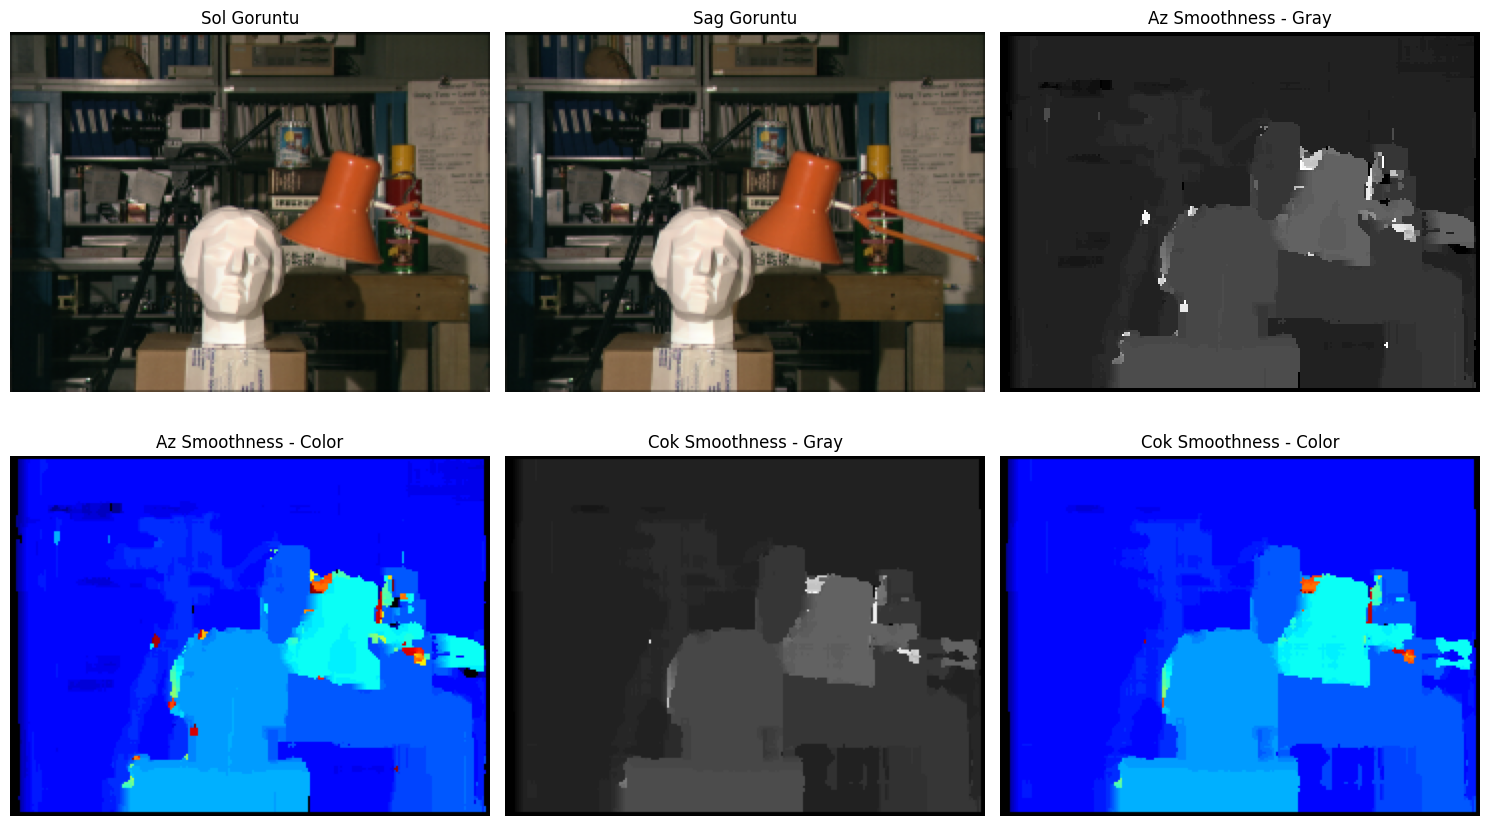

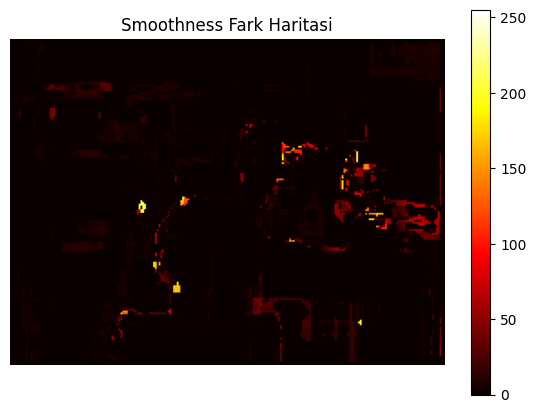

In [18]:
import cv2
import matplotlib.pyplot as plt

images = [
    ("sgbc_sol.png", "Sol Goruntu"),
    ("sgbc_sag.png", "Sag Goruntu"),
    ("sgbc_az_gray.png", "Az Smoothness - Gray"),
    ("sgbc_az_color.png", "Az Smoothness - Color"),
    ("sgbc_cok_gray.png", "Cok Smoothness - Gray"),
    ("sgbc_cok_color.png", "Cok Smoothness - Color")
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (nom, titre) in zip(axes.flat, images):
    path = "/content/" + nom
    img = cv2.imread(path)

    if img is None:
        print("Missing:", path)
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    ax.set_title(titre)
    ax.axis("off")

plt.tight_layout()
plt.show()

fark = cv2.imread("/content/sgbc_fark.png", 0)

if fark is not None:
    plt.figure(figsize=(7, 5))
    plt.imshow(fark, cmap="hot", vmin=0, vmax=255)
    plt.title("Smoothness Fark Haritasi")
    plt.colorbar()
    plt.axis("off")
    plt.show()

In [19]:
!sudo apt-get update -qq
!sudo apt-get install -y libopencv-dev pkg-config
!pkg-config --modversion opencv4

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
pkg-config is already the newest version (1.8.1-2build1).
0 upgraded, 0 newly installed, 0 to remove and 114 not upgraded.
4.6.0


In [20]:
%%writefile /content/sparse_dense.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <vector>
#include <chrono>
#include <algorithm>
#include <cmath>

using namespace cv;
using namespace std;

const int BLOK = 5;
const int MAX_DISP = 48;

int SAD(const Mat& sol, const Mat& sag, int x1, int x2, int y) {
    int toplam = 0;
    int r = BLOK / 2;

    for (int j = -r; j <= r; j++) {
        for (int i = -r; i <= r; i++) {
            int a = sol.at<uchar>(y+j, x1+i);
            int b = sag.at<uchar>(y+j, x2+i);
            toplam += abs(a-b);
        }
    }

    return toplam;
}

Mat eslestir(const Mat& sol, const Mat& sag,
             const Mat& kenarSol, const Mat& kenarSag,
             bool seyrek, bool ters) {

    Mat sonuc(sol.size(), CV_16SC1, Scalar(-1));
    int r = BLOK / 2;

    Mat genisKenar;
    Mat eleman = getStructuringElement(MORPH_RECT, Size(3,1));
    dilate(kenarSag, genisKenar, eleman);

    for (int y = r; y < sol.rows-r; y++) {
        for (int x = r; x < sol.cols-r; x++) {

            if (seyrek && kenarSol.at<uchar>(y,x) == 0)
                continue;

            int enIyi = -1;
            int enDusuk = 1000000000;

            for (int d = 0; d <= MAX_DISP; d++) {
                int xr = ters ? x+d : x-d;

                if (xr-r < 0 || xr+r >= sag.cols)
                    continue;

                if (seyrek && genisKenar.at<uchar>(y,xr) == 0)
                    continue;

                int puan = SAD(sol, sag, x, xr, y);

                if (puan < enDusuk) {
                    enDusuk = puan;
                    enIyi = d;
                }
            }

            if (enIyi >= 0)
                sonuc.at<short>(y,x) = enIyi;
        }
    }

    return sonuc;
}

void kaydet(const Mat& disp, string isim) {
    Mat gri = Mat::zeros(disp.size(), CV_8UC1);
    Mat maske = disp >= 0;

    for (int y = 0; y < disp.rows; y++) {
        for (int x = 0; x < disp.cols; x++) {
            short d = disp.at<short>(y,x);

            if (d >= 0)
                gri.at<uchar>(y,x) =
                    saturate_cast<uchar>(255.0 * d / MAX_DISP);
        }
    }

    Mat renkli;
    applyColorMap(gri, renkli, COLORMAP_JET);
    renkli.setTo(Scalar(0,0,0), ~maske);

    imwrite("/content/" + isim + "_gray.png", gri);
    imwrite("/content/" + isim + "_color.png", renkli);
}

double tutarlilik(const Mat& ileri, const Mat& geri,
                  const Mat& kenar, int& kontrol) {

    int uygun = 0;
    kontrol = 0;

    for (int y = 0; y < ileri.rows; y++) {
        for (int x = 0; x < ileri.cols; x++) {

            if (kenar.at<uchar>(y,x) == 0)
                continue;

            int d = ileri.at<short>(y,x);
            if (d < 0)
                continue;

            int xr = x-d;
            if (xr < 0 || xr >= geri.cols)
                continue;

            int dr = geri.at<short>(y,xr);
            if (dr < 0)
                continue;

            kontrol++;

            if (abs(d-dr) <= 1)
                uygun++;
        }
    }

    if (kontrol == 0)
        return 0;

    return 100.0 * uygun / kontrol;
}

int main() {
    Mat sol = imread("/content/scene1.row3.col1.ppm");
    Mat sag = imread("/content/scene1.row3.col3.ppm");

    if (sol.empty() || sag.empty()) {
        cout << "HATA: Stereo resimleri bulunamadi!" << endl;
        return 1;
    }

    if (sol.size() != sag.size()) {
        cout << "HATA: Goruntu boyutlari farkli!" << endl;
        return 1;
    }

    int w = min(240, sol.cols);
    int h = max(1, sol.rows * w / sol.cols);

    if (w <= MAX_DISP + BLOK || h <= BLOK) {
        cout << "HATA: Goruntu boyutlari cok kucuk!" << endl;
        return 1;
    }

    resize(sol, sol, Size(w,h));
    resize(sag, sag, Size(w,h));

    Mat griSol, griSag;
    cvtColor(sol, griSol, COLOR_BGR2GRAY);
    cvtColor(sag, griSag, COLOR_BGR2GRAY);

    Mat kenarSol, kenarSag;
    Canny(griSol, kenarSol, 60, 140);
    Canny(griSag, kenarSag, 60, 140);

    imwrite("/content/sol.png", sol);
    imwrite("/content/sag.png", sag);
    imwrite("/content/kenar_sol.png", kenarSol);
    imwrite("/content/kenar_sag.png", kenarSag);

    auto basla1 = chrono::steady_clock::now();

    Mat sparse = eslestir(
        griSol, griSag, kenarSol, kenarSag, true, false
    );

    auto bitir1 = chrono::steady_clock::now();

    auto basla2 = chrono::steady_clock::now();

    Mat dense = eslestir(
        griSol, griSag, kenarSol, kenarSag, false, false
    );

    auto bitir2 = chrono::steady_clock::now();

    Mat sparseGeri = eslestir(
        griSag, griSol, kenarSag, kenarSol, true, true
    );

    Mat denseGeri = eslestir(
        griSag, griSol, kenarSag, kenarSol, false, true
    );

    kaydet(sparse, "sparse");
    kaydet(dense, "dense");

    double sureSparse =
        chrono::duration<double>(bitir1-basla1).count();

    double sureDense =
        chrono::duration<double>(bitir2-basla2).count();

    int kontrolSparse = 0, kontrolDense = 0;

    double kaliteSparse = tutarlilik(
        sparse, sparseGeri, kenarSol, kontrolSparse
    );

    double kaliteDense = tutarlilik(
        dense, denseGeri, kenarSol, kontrolDense
    );

    int sparsePiksel = countNonZero(sparse >= 0);
    int densePiksel = countNonZero(dense >= 0);
    int kenarPiksel = countNonZero(kenarSol);

    cout << "\n=== SPARSE / DENSE KARSILASTIRMA ===" << endl;

    cout << "Kenar piksel sayisi: "
         << kenarPiksel << endl;

    cout << "\nSPARSE STEREO" << endl;
    cout << "Sure: " << sureSparse << " saniye" << endl;
    cout << "Eslesen piksel: " << sparsePiksel << endl;
    cout << "Sag-sol tutarlilik: " << kaliteSparse << "%" << endl;
    cout << "Kontrol edilen: " << kontrolSparse << endl;

    cout << "\nDENSE STEREO" << endl;
    cout << "Sure: " << sureDense << " saniye" << endl;
    cout << "Eslesen piksel: " << densePiksel << endl;
    cout << "Sag-sol tutarlilik: " << kaliteDense << "%" << endl;
    cout << "Kontrol edilen: " << kontrolDense << endl;

    cout << "\nTum goruntuler kaydedildi!" << endl;

    return 0;
}

Writing /content/sparse_dense.cpp


In [21]:
!g++ -std=c++17 -O2 /content/sparse_dense.cpp -o /content/sparse_dense $(pkg-config --cflags --libs opencv4) && /content/sparse_dense


=== SPARSE / DENSE KARSILASTIRMA ===
Kenar piksel sayisi: 7737

SPARSE STEREO
Sure: 0.00974404 saniye
Eslesen piksel: 7143
Sag-sol tutarlilik: 89.6821%
Kontrol edilen: 5505

DENSE STEREO
Sure: 0.0832257 saniye
Eslesen piksel: 41536
Sag-sol tutarlilik: 88.0223%
Kontrol edilen: 7180

Tum goruntuler kaydedildi!


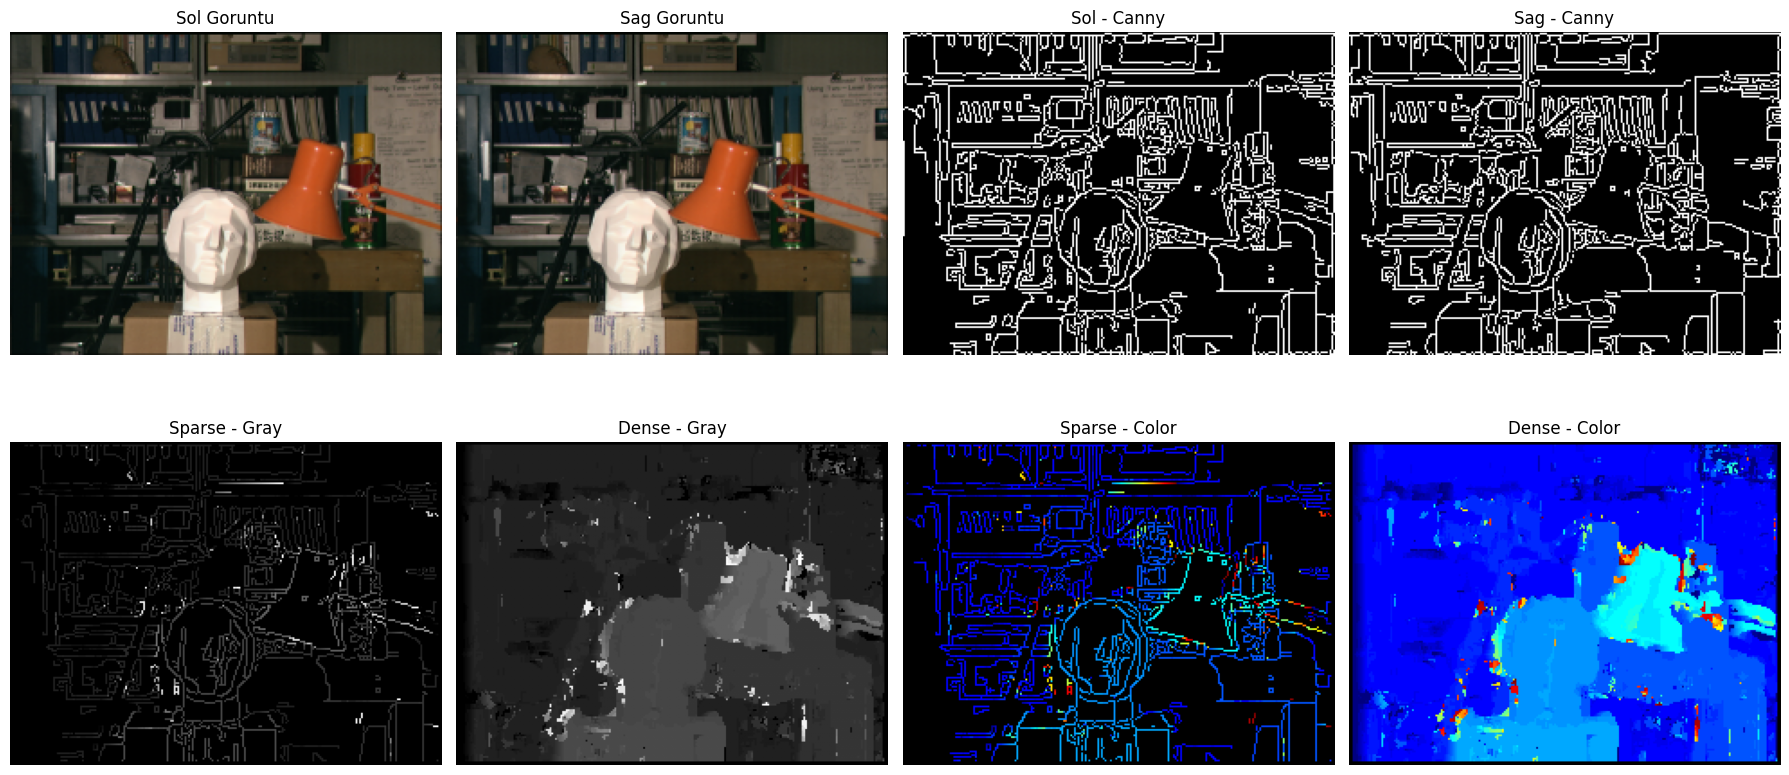

In [22]:
import cv2
import matplotlib.pyplot as plt

images = [
    ("sol.png", "Sol Goruntu"),
    ("sag.png", "Sag Goruntu"),
    ("kenar_sol.png", "Sol - Canny"),
    ("kenar_sag.png", "Sag - Canny"),
    ("sparse_gray.png", "Sparse - Gray"),
    ("dense_gray.png", "Dense - Gray"),
    ("sparse_color.png", "Sparse - Color"),
    ("dense_color.png", "Dense - Color")
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, (nom, titre) in zip(axes.flat, images):
    yol = "/content/" + nom
    img = cv2.imread(yol, cv2.IMREAD_UNCHANGED)

    if img is None:
        print("Missing:", yol)
    elif img.ndim == 2:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    ax.set_title(titre)
    ax.axis("off")

plt.tight_layout()
plt.savefig("/content/sparse_dense_sonuclari.png", dpi=150)
plt.show()